# AIDO-SOH — Acquisition-Invariant Degradation Observer (research prototype)

**Question:** Does a learned *acquisition-consistency objective* improve cross-cell SOH forecasts when charging features are incomplete?

**Models (matched backbone):** `clean_transformer` (clean inputs), `masked_transformer` (mask augmentation), `aido_consistency` (same masked training + representation consistency + missing-observation uncertainty objective).

**Scope warning:** This notebook operates on your **five engineered CALCE CX2 cycle features**. Its feature masks simulate *missing summary measurements*, **not physically valid partial charge curves**. A claim about acquisition-protocol invariance requires raw I/V/t charging records, calibrated view generation and new experiments. This is a falsifiable proof-of-concept—not a validated novel architecture or electrochemical PINN.

**Leakage precautions:** no future SOH or forecast-horizon features; battery-disjoint splits; scaling fit on training only; no sequences crossing missing cycle ordinals; same deterministic test masks for all models; no test-selected hyperparameters. It does not use raw true SOH as an input feature.

In [11]:
# 0. Install once if required: %pip install torch numpy pandas scikit-learn matplotlib
from pathlib import Path
import os, json, copy, random, time
import numpy as np, pandas as pd, torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
print('Torch', torch.__version__, '| CUDA', torch.cuda.is_available())

Torch 2.11.0+cu128 | CUDA True


## Configuration
`smoke`: short correctness test; **not research results**. `full`: meaningful training. `fixed`: the supplied train/validation/test battery-disjoint split. `lobo`: seven-battery held-out evaluation; the next battery in a fixed sorted order is the *inner validation* battery. Cross-battery conclusions require `full + lobo`.

Training and validation are never merged across folds; feature extraction from raw traces is a future separate phase.

In [12]:
DATA_DIR = Path(r'C:\Projects\Battery_Soh\pre processed ready to use data')
# If running this notebook in an environment without the Windows dataset, set DATA_DIR below.
RUN_MODE = 'full'          # 'smoke' or 'full'
EVAL_PROTOCOL = 'fixed'    # 'fixed' or 'lobo'
SEEDS = (42,) if RUN_MODE == 'smoke' else (42,123,2026)
SEQ_LEN = 12
HORIZONS = (1,3,5)
FEATURES = ['cc_duration_s','cv_duration_s','dva_peak','ic_peak_voltage','ic_peak_width']
BATCH_SIZE = 128 if RUN_MODE == 'smoke' else 256
EPOCHS = 2 if RUN_MODE == 'smoke' else 75
PATIENCE = 2 if RUN_MODE == 'smoke' else 12
MAX_TRAIN_BATCHES = 3 if RUN_MODE == 'smoke' else None
MAX_EVAL_BATCHES = 3 if RUN_MODE == 'smoke' else None
CONSISTENCY_LAMBDA = 0.20  # tune using validation only; compare {0, 0.05, 0.2, 0.5}
UNCERTAINTY_LAMBDA = 0.05 # penalty for declaring lower uncertainty when less evidence is available
OUT = DATA_DIR / 'aido_soh_results' / f'{EVAL_PROTOCOL}_{RUN_MODE}'
OUT.mkdir(parents=True,exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| Output:', OUT, '| Mode:', RUN_MODE, EVAL_PROTOCOL)

Device: cuda | Output: C:\Projects\Battery_Soh\pre processed ready to use data\aido_soh_results\fixed_full | Mode: full fixed


## Input validation and battery-level splits
We require a cycle ordinal and an independently validated SOH label. Complete rows in `train_final_filtered.csv` are used if present; otherwise `train.csv`. Preprocessed values are retained, **not silently refiltered**. For LOBO, all seven cells must be available in input CSVs. Original split rows are concatenated only to construct the seven-cell research pool, while all preprocessing is refit from scratch inside each fold.

In [13]:
REQ=['battery','cycle_ordinal','cycle_start','soh']+FEATURES

def read_csv(path):
    if not path.exists(): raise FileNotFoundError(f'Missing {path}; change DATA_DIR')
    d=pd.read_csv(path)
    absent=set(REQ)-set(d.columns)
    if absent: raise ValueError(f'{path.name} lacks: {sorted(absent)}')
    d=d.copy()
    d['battery']=d['battery'].astype(str)
    d['cycle_ordinal']=pd.to_numeric(d['cycle_ordinal'], errors='coerce')
    d['soh']=pd.to_numeric(d['soh'], errors='coerce')
    d['cycle_start']=pd.to_datetime(d['cycle_start'],errors='coerce')
    for c in FEATURES: d[c]=pd.to_numeric(d[c],errors='coerce')
    d=d.dropna(subset=['battery','cycle_ordinal','soh','cycle_start'])
    d=d.sort_values(['battery','cycle_ordinal','cycle_start']).drop_duplicates(['battery','cycle_ordinal'],keep='first')
    return d.reset_index(drop=True)
train_path=DATA_DIR / ('train_final_filtered.csv' if (DATA_DIR/'train_final_filtered.csv').exists() else 'train.csv')
raw_train=read_csv(train_path); raw_val=read_csv(DATA_DIR/'validation.csv'); raw_test=read_csv(DATA_DIR/'test.csv')
print('Rows:',{k:len(v) for k,v in [('train',raw_train),('val',raw_val),('test',raw_test)]})
print('Batteries:',{k:sorted(v.battery.unique()) for k,v in [('train',raw_train),('val',raw_val),('test',raw_test)]})
assert len(set(raw_train.battery)&set(raw_val.battery))==0
assert len(set(raw_train.battery)&set(raw_test.battery))==0
assert len(set(raw_val.battery)&set(raw_test.battery))==0
pool=pd.concat([raw_train,raw_val,raw_test],ignore_index=True)

def make_folds():
    if EVAL_PROTOCOL=='fixed':
        return [{'name':'fixed_CX2_38','train':raw_train,'val':raw_val,'test':raw_test,'heldout':'+'.join(sorted(raw_test.battery.unique()))}]
    batteries=sorted(pool.battery.unique())
    if len(batteries)<3: raise ValueError('LOBO requires at least 3 batteries')
    folds=[]
    for i,heldout in enumerate(batteries):
        val=batteries[(i+1)%len(batteries)]
        folds.append({'name':'heldout_'+heldout,'heldout':heldout,
                      'train':pool[~pool.battery.isin([heldout,val])].copy(),
                      'val':pool[pool.battery==val].copy(),
                      'test':pool[pool.battery==heldout].copy()})
    return folds
folds=make_folds()
print('Folds:', [(f['heldout'],len(f['train']),len(f['val']),len(f['test'])) for f in folds])

Rows: {'train': 7690, 'val': 1743, 'test': 1477}
Batteries: {'train': ['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_37'], 'val': ['CX2_36'], 'test': ['CX2_38']}
Folds: [('CX2_38', 7690, 1743, 1477)]


## Window generator
For each origin cycle \(k\), use only the previous 12 feature vectors through \(k\) and forecast labels at \(k+1,k+3,k+5\). Require **all cycles** in the historical/future path to be consecutive, including cycles between horizons. This is conservative and prevents mixing across dropped/censored cycles.

Missing feature values are median-imputed from train data, then standardized. Their availability bits are supplied to the network; view corruption is applied **after scaling** with zero = normalized training mean. Large source-recording gaps are not labeled 'rest'.

In [14]:
def build_scaler(train):
    med=train[FEATURES].median().fillna(0.0)
    x=train[FEATURES].fillna(med)
    sc=StandardScaler().fit(x.to_numpy(dtype=np.float32))
    return med,sc

def make_windows(frame,med,sc,seq_len=SEQ_LEN,horizons=HORIZONS):
    Xs, Ms, Ys, IDs=[],[],[],[]
    H=max(horizons)
    for battery,g in frame.groupby('battery',sort=True):
        g=g.sort_values('cycle_ordinal').reset_index(drop=True)
        original=g[FEATURES].notna().to_numpy(dtype=np.float32)
        scaled=sc.transform(g[FEATURES].fillna(med).to_numpy(dtype=np.float32)).astype(np.float32)
        scaled=np.nan_to_num(scaled,nan=0,posinf=0,neginf=0)
        cyc=g.cycle_ordinal.to_numpy(dtype=np.int64)
        y=g.soh.to_numpy(dtype=np.float32)
        for end in range(seq_len-1, len(g)-H):
            start=end-seq_len+1
            if not np.all(np.diff(cyc[start:end+H+1])==1): continue
            if not np.isfinite(y[end+np.array(horizons)]).all(): continue
            Xs.append(scaled[start:end+1]);Ms.append(original[start:end+1]);Ys.append(y[end+np.array(horizons)])
            IDs.append((battery,int(cyc[end])))
    if not Xs: raise RuntimeError('Zero windows. Check filtered cycle ordinals, sequence length, and forecast horizon.')
    return {'x':np.stack(Xs).astype(np.float32),'mask':np.stack(Ms).astype(np.float32),
            'y':np.stack(Ys).astype(np.float32),'ids':IDs}

def prepare_fold(f):
    med,sc=build_scaler(f['train'])
    packs={k:make_windows(f[k],med,sc) for k in ('train','val','test')}
    return med,sc,packs

med0,sc0,packs0=prepare_fold(folds[0]);print('Window counts:', {k:len(v['y']) for k,v in packs0.items()})
print('Input:',packs0['train']['x'].shape,'Targets:',packs0['train']['y'].shape)
assert packs0['train']['x'].shape[1:] == (SEQ_LEN,len(FEATURES))

Window counts: {'train': 2853, 'val': 666, 'test': 555}
Input: (2853, 12, 5) Targets: (2853, 3)


## Acquisition views
* `clean`: all truly present features.
* `no_cc` / `no_cv`: entire CC or CV feature withheld.
* `random30`: independently drop 30% of available feature-time entries.
* `history_block`: hide a contiguous segment of historical observations.

For training, generate independent corruptions per batch. The AIDO loss aligns **complete versus partial feature-view representations** only when sufficient measurements survive. It is not guaranteed to be invariant to uninformative or contradictory views. Held-out masks are generated from sample identity, scenario, and a fixed integer seed, so every model sees exactly the same missingness.

In [15]:
SCENARIOS=['clean','no_cc','no_cv','random30','history_block']
def make_view(x,mask,scenario,rng):
    m=mask.copy()
    b,t,f=m.shape
    if scenario=='no_cc': m[:,:,0]=0
    elif scenario=='no_cv': m[:,:,1]=0
    elif scenario=='random30': m *= (rng.random(m.shape)>0.30).astype(np.float32)
    elif scenario=='history_block':
        block=max(1,t//3)
        for i in range(b):
            st=int(rng.integers(0,t-block+1))
            m[i,st:st+block,:]=0
    elif scenario!='clean': raise ValueError(scenario)
    return x*m, m

def train_view(x,m,rng):
    # Mix several observation patterns to prevent specialization to one failure case.
    choice=['clean','no_cc','no_cv','random30','history_block']
    result_x=np.empty_like(x);result_m=np.empty_like(m)
    for i in range(len(x)):
        xx,mm=make_view(x[i:i+1],m[i:i+1],choice[int(rng.integers(len(choice)))],rng)
        result_x[i]=xx[0];result_m[i]=mm[0]
    return result_x,result_m

def scenarios_for_pack(pack):
    views={}
    for j,s in enumerate(SCENARIOS):
        rng=np.random.default_rng(9171+j)
        views[s]=make_view(pack['x'],pack['mask'],s,rng)
    return views

v=scenarios_for_pack(packs0['val']);assert (v['no_cc'][1][:,:,0]==0).all()
print('Test views:',list(v))

Test views: ['clean', 'no_cc', 'no_cv', 'random30', 'history_block']


## Matched model backbone
The baseline and AIDO architectures use the **same Transformer and two output heads**. The prediction heads output SOH mean and log-variance (uncertainty). AIDO adds only training objectives, not extra test-time parameters.

**Physics status:** AIDO contains no validated electrochemical PDE. The objective is feature-observation consistency under missingness, not a proof of physical invariance.

In [16]:
class SOHTransformer(nn.Module):
    def __init__(self,features=len(FEATURES),seq_len=SEQ_LEN,d_model=48,layers=2,heads=4,dropout=.10):
        super().__init__()
        self.input=nn.Linear(features*2,d_model)
        self.pos=nn.Parameter(torch.zeros(1,seq_len,d_model))
        layer=nn.TransformerEncoderLayer(d_model,heads,dim_feedforward=d_model*2,dropout=dropout,
                                          batch_first=True,norm_first=True,activation='gelu')
        self.enc=nn.TransformerEncoder(layer,layers,enable_nested_tensor=False)
        self.norm=nn.LayerNorm(d_model)
        self.pred=nn.Sequential(nn.Linear(d_model,64),nn.GELU(),nn.Linear(64,len(HORIZONS)))
        self.logvar=nn.Sequential(nn.Linear(d_model,32),nn.GELU(),nn.Linear(32,len(HORIZONS)))
        nn.init.constant_(self.logvar[-1].bias,-7.0)
    def forward(self,x,mask):
        z=self.input(torch.cat([x*mask,mask],dim=-1))+self.pos
        z=self.norm(self.enc(z)[:,-1,:])
        mean=self.pred(z)
        logvar=self.logvar(z).clamp(-11,-1.5)
        return mean,logvar,z

def gaussian_nll(mean,logvar,target):
    return 0.5*(torch.exp(-logvar)*(target-mean).square()+logvar).mean()

def weighted_alignment(z_full,z_partial,m_partial):
    import torch.nn.functional as F
    frac=m_partial.mean(dim=(1,2))
    weights=(frac>=0.20).to(z_full.dtype)*frac
    similarity=(F.normalize(z_full,dim=-1)-F.normalize(z_partial,dim=-1)).square().sum(dim=-1)
    return (similarity*weights).sum()/weights.sum().clamp_min(1.0)

def uncertainty_order_penalty(lv_full,lv_partial,m_partial):
    # If evidence is reduced, discourage a lower uncertainty than clean-view output.
    evidence_reduced=(m_partial.mean((1,2))<0.999).float().unsqueeze(1)
    return (torch.relu(lv_full.detach()-lv_partial)*evidence_reduced).mean()

m=SOHTransformer().to(DEVICE)
with torch.no_grad():
    dummy=torch.zeros(2,SEQ_LEN,len(FEATURES),device=DEVICE)
    out=m(dummy,dummy);print('Model outputs:',[z.shape for z in out]);print('Parameters:',sum(q.numel() for q in m.parameters()))

Model outputs: [torch.Size([2, 3]), torch.Size([2, 3]), torch.Size([2, 48])]
Parameters: 44118


## Training and validation
All methods see the same complete windows. `clean_transformer` trains only on complete features; `masked_transformer` and `aido_consistency` use the same train-time masks and two-view supervised Gaussian NLL. **Only AIDO adds** the stop-gradient representation consistency and the uncertainty-order penalty. That isolates the proposed training objective against strong mask augmentation.

Model selection uses only clean + no-CC + random30 *validation* RMSE; test data does not affect the search or checkpoint selection. Equal epoch budgets across methods.

In [17]:
def seed_everything(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

def evaluate(model,pack,scenario,max_batches=None):
    model.eval();x,m=scenarios_for_pack(pack)[scenario];y=pack['y']
    preds=[];logvars=[];targets=[]
    with torch.no_grad():
        for bi,start in enumerate(range(0,len(y),BATCH_SIZE)):
            if max_batches is not None and bi>=max_batches:break
            xx=torch.from_numpy(x[start:start+BATCH_SIZE]).to(DEVICE)
            mm=torch.from_numpy(m[start:start+BATCH_SIZE]).to(DEVICE)
            mu,lv,_=model(xx,mm)
            preds.append(mu.cpu().numpy());logvars.append(lv.cpu().numpy());targets.append(y[start:start+BATCH_SIZE])
    return np.concatenate(targets),np.concatenate(preds),np.concatenate(logvars)

def selection_score(model,pack):
    rm=[]
    for s in ['clean','no_cc','random30']:
        y,p,_=evaluate(model,pack,s,MAX_EVAL_BATCHES)
        rm.append(float(np.sqrt(np.mean((y-p)**2))))
    return float(np.mean(rm))

def fit_model(kind,pack,seed,folder):
    seed_everything(seed)
    model=SOHTransformer().to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=5e-4,weight_decay=1e-4)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=EPOCHS,eta_min=5e-5)
    dataset=TensorDataset(torch.from_numpy(pack['train']['x']),torch.from_numpy(pack['train']['mask']),torch.from_numpy(pack['train']['y']))
    loader=DataLoader(dataset,batch_size=BATCH_SIZE,shuffle=True,num_workers=0,pin_memory=(DEVICE.type=='cuda'))
    rng=np.random.default_rng(seed+123456)
    best=np.inf;best_state=None;best_epoch=0;patience=0;hist=[]
    for ep in range(1,EPOCHS+1):
        model.train();total=0;count=0
        for bi,(x,m,y) in enumerate(loader):
            if MAX_TRAIN_BATCHES is not None and bi>=MAX_TRAIN_BATCHES:break
            xx=x.numpy();mm=m.numpy();
            if kind!='clean_transformer':
                xa,ma=train_view(xx,mm,rng)
                xa=torch.from_numpy(xa).to(DEVICE)
                ma=torch.from_numpy(ma).to(DEVICE)
            x=x.to(DEVICE);m=m.to(DEVICE);y=y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            mu,lv,z=model(x,m)
            loss=gaussian_nll(mu,lv,y)
            if kind!='clean_transformer':
                mup,lvp,zp=model(xa,ma)
                loss=0.5*(loss+gaussian_nll(mup,lvp,y))
                if kind=='aido_consistency':
                    loss=loss+CONSISTENCY_LAMBDA*weighted_alignment(z.detach(),zp,ma)
                    loss=loss+UNCERTAINTY_LAMBDA*uncertainty_order_penalty(lv,lvp,ma)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.)
            opt.step();total+=float(loss.item());count+=1
        scheduler.step()
        score=selection_score(model,pack['val'])
        hist.append({'epoch':ep,'train_loss':total/max(count,1),'val_selection_rmse':score})
        if score<best-1e-6:
            best=score;best_state=copy.deepcopy(model.state_dict());best_epoch=ep;patience=0
        else:patience+=1
        if ep==1 or ep%10==0:print(f'  {kind} seed={seed} ep={ep} val={score:.5f}')
        if patience>=PATIENCE:break
    model.load_state_dict(best_state)
    folder.mkdir(parents=True,exist_ok=True)
    torch.save({'model':best_state,'best_epoch':best_epoch,'val_score':best,
                'model_config':{'seq_len':SEQ_LEN,'features':FEATURES,'horizons':HORIZONS},
                'seed':seed,'kind':kind},folder/f'{kind}_seed{seed}.pt')
    pd.DataFrame(hist).to_csv(folder/f'{kind}_seed{seed}_history.csv',index=False)
    return model,best,best_epoch

print('Training functions ready')

Training functions ready


## Execute experiments
In `smoke`, one fold, seed 42, two epochs: only tests that the code runs. `full/fixed`: original train/validation/test. `full/lobo`: run all held-out cells (computationally expensive). Saved measurements include per-cell, per-horizon and scenario metrics, plus predictions and all checkpoint metadata.

In [18]:
KINDS=['clean_transformer','masked_transformer','aido_consistency']
all_metrics=[];all_predictions=[];all_selected=[]
active_folds=folds[:1] if RUN_MODE=='smoke' else folds
for fi,f in enumerate(active_folds):
    print('\nFOLD',fi+1,'/',len(active_folds),f['name'],'heldout:',f['heldout'])
    med,sc,packs=prepare_fold(f)
    fold_out=OUT/f['name'];fold_out.mkdir(parents=True,exist_ok=True)
    with open(fold_out/'normalizer.json','w') as file:
        json.dump({'features':FEATURES,'train_median':med.to_dict(),
                   'train_mean':sc.mean_.tolist(),'train_scale':sc.scale_.tolist()},file,indent=2)
    for kind in KINDS:
        for seed in SEEDS:
            model,val,bep=fit_model(kind,packs,seed,fold_out)
            all_selected.append({'fold':f['name'],'heldout':f['heldout'],'kind':kind,'seed':seed,
                                 'validation_score':val,'best_epoch':bep})
            for scenario in SCENARIOS:
                y,p,lv=evaluate(model,packs['test'],scenario,MAX_EVAL_BATCHES)
                for j,h in enumerate(HORIZONS):
                    rmse=float(np.sqrt(np.mean((y[:,j]-p[:,j])**2)))
                    mae=float(np.mean(abs(y[:,j]-p[:,j])))
                    sigma=np.sqrt(np.exp(lv[:,j]))
                    cover=float(np.mean(abs(y[:,j]-p[:,j])<=1.645*sigma))
                    all_metrics.append({'fold':f['name'],'heldout':f['heldout'],'model':kind,'seed':seed,
                                        'scenario':scenario,'horizon':h,'n':len(y),'rmse':rmse,
                                        'mae':mae,'coverage90_gaussian':cover,'mean_width90_gaussian':float(np.mean(3.29*sigma)),
                                        'best_epoch':bep,'val_selection_score':val})
                # Store paired predictions for reproducibility and downstream plots.
                selected_ids=packs['test']['ids'][:len(y)]
                for i,(bat,cycle) in enumerate(selected_ids):
                    for j,h in enumerate(HORIZONS):
                        all_predictions.append({'fold':f['name'],'heldout':f['heldout'],'model':kind,'seed':seed,
                                                'scenario':scenario,'battery':bat,'origin_cycle':cycle,'horizon':h,
                                                'y_true':float(y[i,j]),'y_pred':float(p[i,j]),
                                                'pred_sigma':float(np.sqrt(np.exp(lv[i,j])))})
            del model
            if DEVICE.type=='cuda': torch.cuda.empty_cache()
metrics=pd.DataFrame(all_metrics);selected=pd.DataFrame(all_selected)
metrics.to_csv(OUT/'scenario_metrics.csv',index=False)
selected.to_csv(OUT/'validation_selections.csv',index=False)
pd.DataFrame(all_predictions).to_csv(OUT/'test_predictions.csv',index=False)
summary=metrics.groupby(['model','scenario','horizon'],as_index=False).agg(
    mean_cell_rmse=('rmse','mean'),sd_cell_rmse=('rmse','std'),mean_mae=('mae','mean'),
    mean_coverage90=('coverage90_gaussian','mean'),cells=('heldout','nunique'),runs=('rmse','size'))
summary.to_csv(OUT/'summary.csv',index=False)
print('\nSAVED:',OUT)
print(summary.query("scenario in ['clean','no_cc'] and horizon==5").sort_values(['scenario','mean_cell_rmse']).to_string(index=False))


FOLD 1 / 1 fixed_CX2_38 heldout: CX2_38
  clean_transformer seed=42 ep=1 val=0.12270
  clean_transformer seed=42 ep=10 val=0.07398
  clean_transformer seed=123 ep=1 val=0.26179
  clean_transformer seed=123 ep=10 val=0.08453
  clean_transformer seed=2026 ep=1 val=0.09254
  clean_transformer seed=2026 ep=10 val=0.06183
  masked_transformer seed=42 ep=1 val=0.12928
  masked_transformer seed=42 ep=10 val=0.03523
  masked_transformer seed=42 ep=20 val=0.02143
  masked_transformer seed=42 ep=30 val=0.02177
  masked_transformer seed=42 ep=40 val=0.02059
  masked_transformer seed=123 ep=1 val=0.26326
  masked_transformer seed=123 ep=10 val=0.03267
  masked_transformer seed=123 ep=20 val=0.02860
  masked_transformer seed=123 ep=30 val=0.02173
  masked_transformer seed=123 ep=40 val=0.02333
  masked_transformer seed=2026 ep=1 val=0.10272
  masked_transformer seed=2026 ep=10 val=0.02986
  masked_transformer seed=2026 ep=20 val=0.02317
  masked_transformer seed=2026 ep=30 val=0.01748
  masked_tra

## Paired comparisons and visual inspection
AIDO must beat `masked_transformer`, not merely `clean_transformer`, to attribute gains to its consistency objective. Compare **the same held-out battery, random seed, horizon, and scenario**. Never assert significance from smoke runs or one cell.

model                  aido_gain_vs_masked_transformer_pct  aido_gain_vs_clean_transformer_pct
scenario      horizon                                                                         
clean         1                                      -6.71                               52.64
              3                                      -5.57                               49.66
              5                                     -11.34                               35.49
history_block 1                                     -10.29                               67.21
              3                                     -10.34                               69.62
              5                                     -16.01                               60.51
no_cc         1                                       9.52                               76.65
              3                                       5.79                               69.33
              5                                   

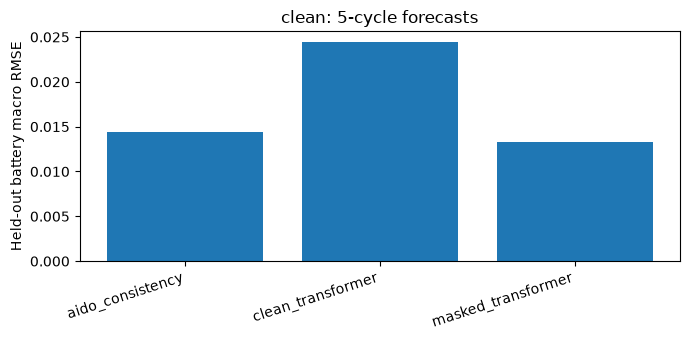

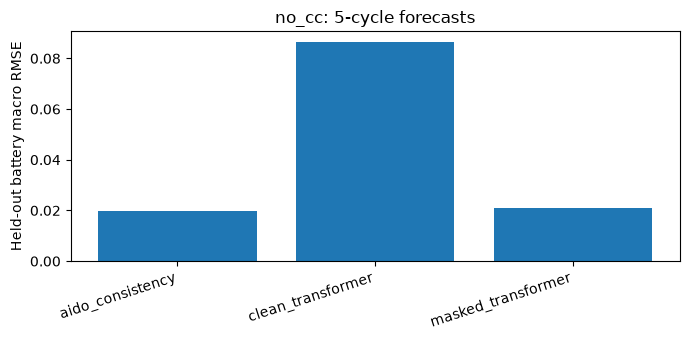

In [19]:
focus=metrics[metrics.scenario.isin(['clean','no_cc','random30','history_block'])]
wide=focus.pivot_table(index=['fold','heldout','seed','scenario','horizon'],columns='model',values='rmse').reset_index()
for reference in ['masked_transformer','clean_transformer']:
    wide[f'aido_gain_vs_{reference}_pct']=100*(wide[reference]-wide['aido_consistency'])/wide[reference]
wide.to_csv(OUT/'paired_improvements.csv',index=False)
print(wide.groupby(['scenario','horizon'])[[c for c in wide if c.startswith('aido_gain_vs_')]].mean().round(2).to_string())
for scenario in ['clean','no_cc']:
    dd=summary[(summary.scenario==scenario)&(summary.horizon==5)]
    plt.figure(figsize=(7,3.5))
    plt.bar(dd.model,dd.mean_cell_rmse)
    plt.ylabel('Held-out battery macro RMSE');plt.title(f'{scenario}: 5-cycle forecasts')
    plt.xticks(rotation=18,ha='right');plt.tight_layout()
    plt.savefig(OUT/f'comparison_{scenario}_h5.png',dpi=145);plt.show()

## Research interpretation checklist

1. **Baseline fairness:** `masked_transformer` uses exactly the same augmentation, network and supervised two-view loss as AIDO; only consistency/uncertainty penalties differ.
2. **Expected failure mode:** AIDO may worsen clean accuracy or force incompatible partial views together. If so, reduce consistency weight or use an evidence-conditioned teacher and revise the hypothesis.
3. **Uncertainty:** Gaussian interval coverage is descriptive, *not calibrated*. A separately reserved calibration split and reliability diagram are needed before operational uncertainty claims.
4. **Battery robustness:** `fixed` has one test cell. `lobo` is necessary to report cell-macro mean, worst-cell performance and paired wins; for manuscript-quality tuning, nest a proper inner-search rather than choosing hyperparameters on outer test outcomes.
5. **Novelty:** Masked battery Transformers, consistency learning and degradation-state observers have precedents. This notebook alone does not demonstrate novelty or outperform prior literature.
6. **Next step for true acquisition invariance:** Extract raw current, voltage, temperature and timestamps per charge event; generate physically valid crop/resampling/noise views *before* any feature extraction, retaining actual coverage masks and operating protocols; compare with masked-curve Transformers and self-supervised baselines on wholly unseen cells/protocols.

**Report files:** `scenario_metrics.csv`, `summary.csv`, `paired_improvements.csv`, `validation_selections.csv`, `test_predictions.csv`, `normalizer.json` and per-seed checkpoints.

In [20]:
manifest={'name':'AIDO-SOH feature-level research prototype','run_mode':RUN_MODE,'protocol':EVAL_PROTOCOL,
          'seeds':SEEDS,'features':FEATURES,'horizons':HORIZONS,'seq_len':SEQ_LEN,
          'consistency_lambda':CONSISTENCY_LAMBDA,'uncertainty_lambda':UNCERTAINTY_LAMBDA,
          'mask_scenarios':SCENARIOS,'raw_curve_study':False,
          'warning':'Feature-level masking is NOT physically valid partial-curve acquisition',
          'train_file':str(train_path),'torch':torch.__version__}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2,default=str))
print('Complete. Results folder:',OUT)

Complete. Results folder: C:\Projects\Battery_Soh\pre processed ready to use data\aido_soh_results\fixed_full
